# Import all packages

In [1]:
using DifferentialEquations
using OrdinaryDiffEq
using DiffEqBase
using Sundials
using ODEInterfaceDiffEq
using Plots
using Measures
using CSV
using DataFrames
# using Turing
# using MCMCChains
using EasyFit
using StatsPlots
using LinearAlgebra
using Random
using Distributions
using OrdinaryDiffEq
Random.seed!(145975);
using CmdStan
using KernelDensity
using LaTeXStrings
using StatsBase
using JLD2
using BlackBoxOptim
using BlackBoxOptim: num_func_evals
using HypothesisTests
using BayesianOptimization, GaussianProcesses

# using CairoMakie
# using PairPlots
# using DataFrames

set_cmdstan_home!("C:\\cmdstan\\cmdstan-2.30.0");

┌ Warning: Environment variable CMDSTAN_HOME not set. Use set_cmdstan_home!.
└ @ CmdStan C:\Users\dgomez\.julia\packages\CmdStan\2vwWj\src\CmdStan.jl:27


# Define Model With no Transporter

In [2]:
# THis is only for the enzyme, no transporter involved!!!!

function PyruvateHP_LDHNoCells!(du, u, p, t)

    Php, Xhp, NADH, NAD, LDH, LDHac, LDHacE, LDHna, LDHP, XhpHyper, PhpHyper, Obs_XhpHyper, Obs_PhpHyper = u;
    T1_X, T1_P, kpl, kbn, kun, kbp, kup, kunE, kbnE, ki, kr, ClNm, ScFm = p;


    du[1] = dPhp = kup*LDHP + kr*LDHna - kbp*LDHac*Php - ki*LDH*Php
    du[2] = dXhp = kpl*LDHP
    du[3] = dNADH = kun*LDHac - kbn*LDH*NADH
    du[4] = dNAD = kunE*LDHacE - kbnE*LDH*NAD
    du[5] = dLDH = kun*LDHac + kr*LDHna + kunE*LDHacE - kbn*LDH*NADH - ki*LDH*Php - kbnE*LDH*NAD
    du[6] = dLDHac = kbn*LDH*NADH + kup*LDHP - kun*LDHac - kbp*LDHac*Php
    du[7] = dLDHacE = kpl*LDHP + kbnE*LDH*NAD - kunE*LDHacE
    du[8] = dLDHna = ki*LDH*Php - kr*LDHna
    du[9] = dLDHP = kbp*LDHac*Php - kup*LDHP - kpl*LDHP
    
    du[10] = dXhpHyper =  dXhp*ClNm - (XhpHyper/T1_X)
    du[11] = dPhpHyper =  dPhp + dLDHna + dLDHP - (PhpHyper/T1_P)

    du[12] = dObs_XhpHyper =  dXhpHyper * (ScFm*0.12)
    du[13] = dObs_PhpHyper =  dPhpHyper * (ScFm*0.12)

end


function PyruvateHP_SolveLDHNoCells(ts, pD, ivss, samps)


    nStat = 13;
    nPar = 14;

    if length(size(pD)) == 1
        pD = reshape(pD,size(pD)[1],1);
    end

    if size(pD)[2] != nPar     
        pD = pD';
    end

    if length(ivss)/nStat > 1
        if size(ivss)[2] != nStat
            ivss = ivss';
        end
    end

    AllSolTest = zeros(length(samps), nStat, length(pD[:,1])); # Simulation of the system observed
    AllSolTest_Off = Array{Any,1}(undef,length(pD[:,1])); # Simulation of the system before we obvserve it (considering time offset). First column is the time vector
    AllSolTest_Tog = Array{Any,1}(undef,length(pD[:,1])); # Previous two together. First column is the time vector. 


    
    for drawInd in collect(1:length(pD[:,1]))
        
        p = pD[drawInd,1:end-1];
        tau = pD[drawInd,end];
        
        if length(ivss)/nStat > 1
            ivss2 = ivss[drawInd,:];
        else
            ivss2 = ivss;
        end
    
        # Account for the time offset
    
        
            prob_off = ODEProblem(PyruvateHP_LDHNoCells!,ivss2,(-tau, 0),p);
            part1_off = DifferentialEquations.solve(prob_off, CVODE_BDF(),reltol=1.0e-9,abstol=1.0e-9);
        
            ivss2 = part1_off.u[end];
        
            prob = ODEProblem(PyruvateHP_LDHNoCells!,ivss2,(ts[1], ts[end]),p);
            part1 = DifferentialEquations.solve(prob, CVODE_BDF(),reltol=1.0e-9,abstol=1.0e-9,saveat=1);
        
        
        AllSolTest[:,:,drawInd]
    
        tmp = zeros(length(part1_off.u), nStat);
    
        
        

        for j in 1:nStat
            AllSolTest[:,j,drawInd] = [part1.u[i][j] for i in 1:length(part1.u)][samps.+1];
            tmp[:,j] = [part1_off.u[i][j] for i in 1:length(part1_off.u)];
        end

        AllSolTest_Off[drawInd] = hcat(part1_off.t, tmp);
        AllSolTest_Tog[drawInd] = vcat(AllSolTest_Off[drawInd][1:end-1, :], hcat(samps, AllSolTest[:,:,drawInd]));
        
        
        
    
    end

    return AllSolTest, AllSolTest_Off, AllSolTest_Tog

end

PyruvateHP_SolveLDHNoCells (generic function with 1 method)

In [3]:
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\BayesianInference\\FunctionsBayesInfs.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\InitalParameterFitPriorDef\\ModelFunctionsAll.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\FunctionsBayesOED.jl")

include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\FunctionsInferenceScallable.jl")

simDwnExp2 (generic function with 2 methods)

# Load Posteriors

In [4]:
poster1 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\\\Results\\PosteriorCompetitiveRepressionExpScal_Iter1_Try1.csv", DataFrame))
poster2 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\\\Results\\PosteriorCompetitiveRepressionExpScal_Iter2_Try1.csv", DataFrame))
poster3 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\\\Results\\PosteriorCompetitiveRepressionExpScal_Iter3_Try1.csv", DataFrame))
poster4 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\\\Results\\PosteriorCompetitiveRepressionExpScal_Iter4_Try1.csv", DataFrame))
poster5 = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\\\Results\\PosteriorCompetitiveRepressionExpScal_Iter4b_Try1.csv", DataFrame));

# Subsample Posterior

In [5]:
Random.seed!(654358)
smps = 400
ins = sample(1:8000, smps, replace = false)

smp_T = poster3[ins, :];
smp_NT = poster3[ins, vcat(1:2, 4:17)];

# Simulation of dDNP conditions

### With Transporter

In [25]:
tsC2 = collect(0:395)[1:5:end]
ts = 0:tsC2[end];
samps = convert.(Int, tsC2)
conce = collect(0.1:0.1:40)

rep = false

if !isfile("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\NMRExpSims_WT.jld") || rep == true

    println(1)

    smms = Array{Any}(undef, length(conce), smps)

    for mm in 1:length(conce)
        for jj in 1:smps

            ivss = [round(conce[mm], digits = 1)*1000, 0, 0, smp_T[jj, end-2], smp_T[jj, end-1], smp_T[jj, end], 0, 0, 0, 0, 0, round(conce[mm], digits = 1)*1000, 0, round(conce[mm], digits = 1)*1000*(26.791799999999974*0.12)]
            SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp_Scall(ts, vcat(smp_T[jj, 1:end-3], 0), ivss, samps)

            smms[mm, jj] = SimulsAll
        end
    end

    JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\NMRExpSims_WT.jld", "smms", smms)
else
    
    smms = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\NMRExpSims_WT.jld")["smms"];
    println(2)
end

2


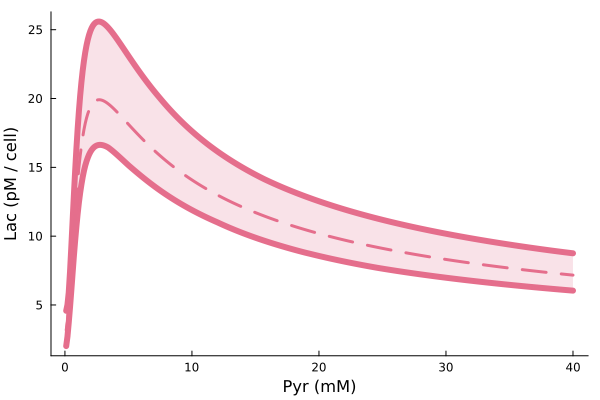

In [26]:
upP = [percentile([smms[i,jj][end,3,1] for jj in 1:smps], 99.5) for i in 1:length(conce)];
lwP = [percentile([smms[i,jj][end,3,1] for jj in 1:smps],  0.5) for i in 1:length(conce)];
mdP = [mean([smms[i,jj][end,3,1] for jj in 1:smps]) for i in 1:length(conce)];

ppt = plot(size=(600,400), grid=false)

plot!(conce, upP.*1e+6, label="", xlabel="Pyr (mM)", ylabel = "Lac (pM / cell)",
    linewidth=6, colour="#e56e8c")
plot!(conce, lwP.*1e+6, label="", xlabel="Pyr (mM)", ylabel = "Lac (pM / cell)",
    linewidth=6, colour="#e56e8c")
plot!(conce, upP.*1e+6, fillrange=lwP.*1e+6, label="", color="#e56e8c", fillalpha=0.2)
plot!(conce, mdP.*1e+6, colour="#e56e8c", label = "", linewidth = 3, style =:dash)

In [31]:
conce[findfirst(mdP .== maximum(mdP))]

2.7

In [10]:
insmx = [findfirst(maximum(smms[i,jj][:,13,1]) .== smms[i,jj][:,13,1]) for jj in 1:smps for i in 1:length(conce)]

mean(samps[insmx]), std(samps[insmx])


(55.23671875, 3.8286126204690234)

In [12]:
permx = []
for jj in 1:smps 
    for i in 1:length(conce)
        timm = findfirst(maximum(smms[i,jj][:,13,1]) .== smms[i,jj][:,13,1])
        push!(permx, (smms[i,jj][timm,3,1]/smms[i,jj][end,3,1])*100)
    end
end

mean(permx), std(permx)

(60.361964086259945, 3.2104861039369266)

### Without Transporter

In [32]:
tsC2 = collect(0:395)[1:5:end]
ts = 0:tsC2[end];
samps = convert.(Int, tsC2)
conce2 = vcat(LinRange(0.001,5,100), LinRange(5,40,300))

rep = false

if !isfile("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\NMRExpSims_WOT.jld") || rep == true

    println(1)

    smms2 = Array{Any}(undef, length(conce2), smps)

    for mm in 1:length(conce2)
        for jj in 1:smps

            ivss = [round(conce2[mm], digits = 1)*1000, 0, smp_NT[jj, end-2], smp_NT[jj, end-1], smp_NT[jj, end], 0, 0, 0, 0, 0, round(conce2[mm], digits = 1)*1000, 0, round(conce2[mm], digits = 1)*1000*(26.79*0.12)]
            SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_SolveLDHNoCells(ts, vcat(smp_NT[jj, 1:end-3], 0), ivss, samps)

            smms2[mm, jj] = SimulsAll

        end

    end

    JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\NMRExpSims_WOT.jld", "smms2", smms2)

else
    
    smms2 = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\NMRExpSims_WOT.jld")["smms2"];
    println(2)
end

2


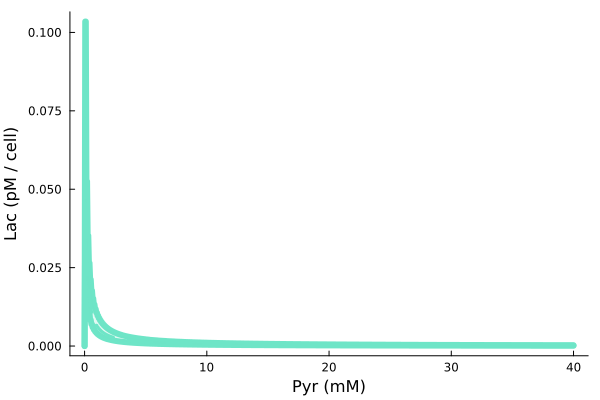

In [33]:
upP2 = [percentile([smms2[i,jj][end,2,1] for jj in 1:smps], 99.5) for i in 1:length(conce2)];
lwP2 = [percentile([smms2[i,jj][end,2,1] for jj in 1:smps],  0.5) for i in 1:length(conce2)];
mdP2 = [mean([smms2[i,jj][end,2,1] for jj in 1:smps]) for i in 1:length(conce2)];

ppt = plot(size=(600,400), grid=false)

plot!(conce2, upP2.*1e+6, label="", xlabel="Pyr (mM)", ylabel = "Lac (pM / cell)",
    linewidth=6, colour="#6ee5c7")
plot!(conce2, lwP2.*1e+6, label="", xlabel="Pyr (mM)", ylabel = "Lac (pM / cell)",
    linewidth=6, colour="#6ee5c7")
plot!(conce2, upP2.*1e+6, fillrange=lwP2.*1e+6, label="", color="#6ee5c7", fillalpha=0.2)
plot!(conce2, mdP2.*1e+6, colour="#6ee5c7", label = "", linewidth = 3, style =:dash)

In [67]:
ylims(ppt)

(-0.002445359801427835, 0.08395735318235567)

In [34]:
conce2[findfirst(mdP2 .== maximum(mdP2))]

0.0514949494949495

### Together

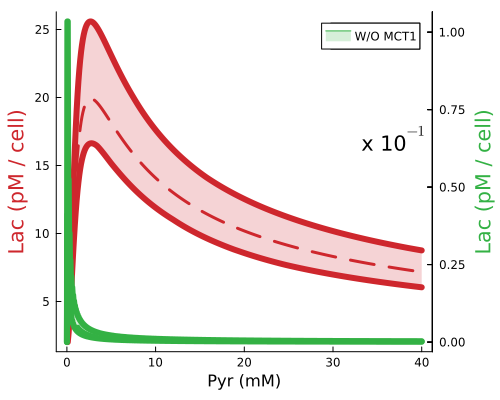

In [15]:
ppt = plot(size=(500,400), grid=false)#, xscale=:log10)

plot!(conce, upP.*1e+6, label="", xlabel="Pyr (mM)", ylabel = "Lac (pM / cell)",
    linewidth=6, colour="#ce272dff", yguidefont = font("#ce272dff"))
plot!(conce, lwP.*1e+6 , label="", xlabel="Pyr (mM)",
    linewidth=6, colour="#ce272dff")
plot!(conce, upP.*1e+6 , fillrange=lwP.*1e+6 , label="W/ MCT1", color="#ce272dff", fillalpha=0.2)
plot!(conce, mdP.*1e+6 , colour="#ce272dff", label = "", linewidth = 3, style =:dash)


annotate!(37, 17, "x 10"*L"^{-1}")


plot!(twinx(),conce2, upP2.*1e+6 .*10, label="", xlabel="", ylabel = "Lac (pM / cell)",
    linewidth=6, colour="#33b144ff", ylim = (-0.003103888683654542, 0.10656684480547254) .*10, yguidefont = font("#33b144ff"))
plot!(twinx(),conce2, lwP2.*1e+6 .*10, label="", xlabel="", ylabel = "",
    linewidth=6, colour="#33b144ff", ylim = (-0.003103888683654542, 0.10656684480547254) .*10, yformatter=_->"")
plot!(twinx(),conce2, upP2.*1e+6 .*10, fillrange=lwP2.*1e+6 .*10, label="W/O MCT1", color="#33b144ff", fillalpha=0.2, ylim = (-0.003103888683654542, 0.10656684480547254) .*10, yformatter=_->"")
plot!(twinx(),conce2, mdP2.*1e+6 .*10, colour="#33b144ff", label = "", linewidth = 3, style =:dash, ylim = (-0.003103888683654542, 0.10656684480547254) .*10, yformatter=_->"")

# savefig(ppt,"C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure7Stuff\\dDNPExperimentSims.svg")

display(ppt)

# Simulation of LDH Assay Conditions

### With transporter

In [16]:
# Option 1: We consider that a single cell has the amount of LDH that 1e5 cell have. Hence, for volume, we should consider the 200 uL of the well

tsC2 = collect(0:395)[1:5:end]
ts = 0:tsC2[end];
samps = convert.(Int, tsC2)
conce = collect(0.1:0.1:40)

rep = false

if !isfile("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_WT.jld") || rep == true

    println(1)

    smms4 = Array{Any}(undef, length(conce), smps)

    for mm in 1:length(conce)
        for jj in 1:smps
            uMassey = (((smp_T[jj, end]*8.5e-13)*1e5)/0.0002)

            ivss = [round(conce[mm], digits = 1)*1000, 0, 0, 220, 0, uMassey, 0, 0, 0, 0, 0, round(conce[mm], digits = 1)*1000, 0, round(conce[mm], digits = 1)*1000*(26.791799999999974*0.12)]
            SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp_Scall(ts, vcat(smp_T[jj, 1:end-3], 0), ivss, samps)

            smms4[mm, jj] = SimulsAll

        end

    end

    JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_WT.jld", "smms4", smms4)

else
    
    smms4 = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_WT.jld")["smms4"];
    println(2)
end

2


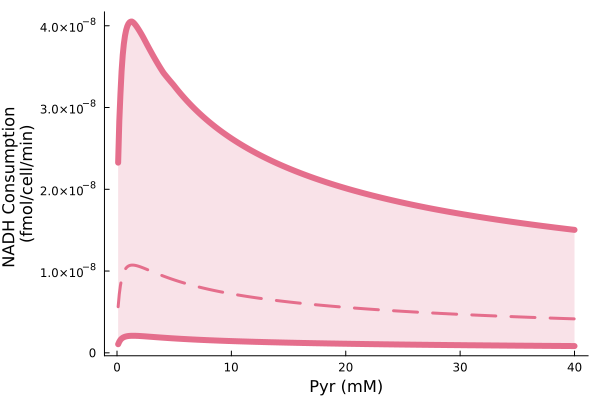

In [17]:
upP3 = [percentile(((((220 .-[smms4[i,jj][13,4,1]+smms4[i,jj][13,7,1]+smms4[i,jj][13,10,1] for jj in 1:smps])*0.0002)./1e5).*1e+9), 99.5) for i in 1:length(conce)];
lwP3 = [percentile(((((220 .-[smms4[i,jj][13,4,1]+smms4[i,jj][13,7,1]+smms4[i,jj][13,10,1] for jj in 1:smps])*0.0002)./1e5).*1e+9),  0.5) for i in 1:length(conce)];
mdP3 = [(((mean(220 .-[smms4[i,jj][13,4,1]+smms4[i,jj][13,7,1]+smms4[i,jj][13,10,1] for jj in 1:smps])*0.0002)./1e5).*1e+9) for i in 1:length(conce)];

ppt = plot(size=(600,400), grid=false)

plot!(conce, upP3, label="", xlabel="Pyr (mM)", ylabel = "NADH Consumption \n(fmol/cell/min)",
    linewidth=6, colour="#e56e8c")
plot!(conce, lwP3, label="", xlabel="Pyr (mM)", 
    linewidth=6, colour="#e56e8c")
plot!(conce, upP3, fillrange=lwP3, label="", color="#e56e8c", fillalpha=0.2)
plot!(conce, mdP3, colour="#e56e8c", label = "", linewidth = 3, style =:dash)

### Without Transporter

We need to go from LDH concentration in a cell to moles, then scale up to the moles of 1e5 cells (amount per assay) and compute the exact molarity in 200 uL of the assay!!!

In [18]:
println("LDH Single Cell (microM)")
println(mean(smp_T[:, end]))

println("LDH Outside 1e5 Cells (microM)")
println((((mean(smp_T[:, end])*8.5e-13)*1e5)/0.0002))

LDH Single Cell (microM)
1.0867702849999998
LDH Outside 1e5 Cells (microM)
0.00046187737112499995


In [19]:
# Option 1: We consider that a single cell has the amount of LDH that 1e5 cell have. Hence, for volume, we should consider the 200 uL of the well. This is the correct one, since this is what we do experimentally

tsC2 = collect(0:395)[1:5:end]
ts = 0:tsC2[end];
samps = convert.(Int, tsC2)
conce3 = vcat(LinRange(0.001,5,100), LinRange(5,40,300))


rep = false

if !isfile("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_WOT.jld") || rep == true

    println(1)

    smms5 = Array{Any}(undef, length(conce3), smps)

    for mm in 1:length(conce3)
        for jj in 1:smps
            uMassey = (((smp_T[jj, end]*8.5e-13)*1e5)/0.0002)

            ivss = [round(conce3[mm], digits = 1)*1000, 0, 220, 0, uMassey, 0, 0, 0, 0, 0, round(conce3[mm], digits = 1)*1000, 0, round(conce3[mm], digits = 1)*1000*(26.791799999999974*0.12)]
            SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_SolveLDHNoCells(ts, vcat(smp_NT[jj, 1:end-3], 0), ivss, samps)

            smms5[mm, jj] = SimulsAll

        end

    end

    JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_WOT.jld", "smms5", smms5)

else
    
    smms5 = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_WOT.jld")["smms5"];
    println(2)
end

2


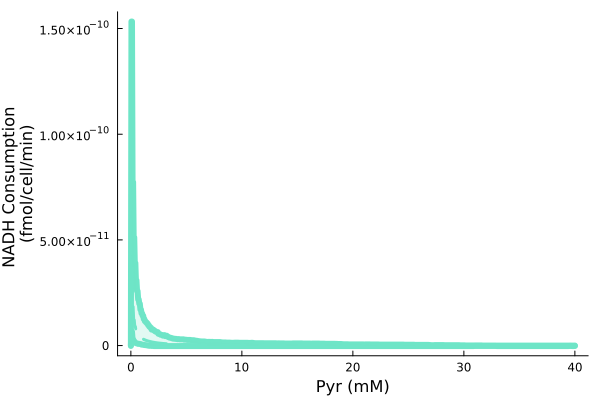

(-4.833199795939438e-12, 1.579059897949264e-10)

In [20]:
upP4 = [percentile(((((220 .-[smms5[i,jj][13,3,1]+smms5[i,jj][13,6,1]+smms5[i,jj][13,9,1] for jj in 1:smps])*0.0002)./1e5).*1e+9), 99.5) for i in 1:length(conce)];
lwP4 = [percentile(((((220 .-[smms5[i,jj][13,3,1]+smms5[i,jj][13,6,1]+smms5[i,jj][13,9,1] for jj in 1:smps])*0.0002)./1e5).*1e+9),  0.5) for i in 1:length(conce)];
mdP4 = [(((mean(220 .-[smms5[i,jj][13,3,1]+smms5[i,jj][13,6,1]+smms5[i,jj][13,9,1] for jj in 1:smps])*0.0002)./1e5).*1e+9) for i in 1:length(conce3)];

ppt2 = plot(size=(600,400), grid=false)

plot!(conce3, upP4, label="", xlabel="Pyr (mM)", ylabel = "NADH Consumption \n(fmol/cell/min)",
    linewidth=6, colour="#6ee5c7")
plot!(conce3, lwP4, label="", xlabel="Pyr (mM)", 
    linewidth=6, colour="#6ee5c7")
plot!(conce3, upP4, fillrange=lwP4, label="", color="#6ee5c7", fillalpha=0.2)
plot!(conce3, mdP4, colour="#6ee5c7", label = "", linewidth = 3, style =:dash)

display(ppt2)

ylims(ppt2)

### Together

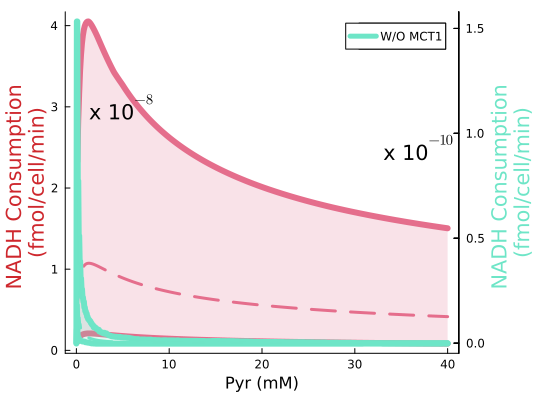

In [21]:
ppt = plot(size=(535,400), grid=false)

plot!(conce, upP3 .*1e8, label="W MCT1", xlabel="Pyr (mM)", ylabel = "NADH Consumption \n(fmol/cell/min)",
    linewidth=6, colour="#e56e8c", yguidefont = font("#ce272dff"))
plot!(conce, lwP3 .*1e8, label="", xlabel="Pyr (mM)", 
    linewidth=6, colour="#e56e8c")
plot!(conce, upP3 .*1e8, fillrange=lwP3 .*1e8, label="", color="#e56e8c", fillalpha=0.2)
plot!(conce, mdP3 .*1e8, colour="#e56e8c", label = "", linewidth = 3, style =:dash)

annotate!(5, 3, "x 10"*L"^{-8}")
annotate!(37, 2.5, "x 10"*L"^{-10}")

plot!(twinx(), conce3, upP4 .*1e10, label="W/O MCT1", xlabel="", ylabel = "NADH Consumption \n(fmol/cell/min)",
    linewidth=6, colour="#6ee5c7", ylim=(-4.833199795939438e-12, 1.579059897949264e-10) .*1e10, yguidefont = font("#6ee5c7"))
plot!(twinx(), conce3, lwP4 .*1e10, label="", xlabel="", 
    linewidth=6, colour="#6ee5c7", ylim=(-4.833199795939438e-12, 1.579059897949264e-10) .*1e10, yformatter=_->"")
plot!(twinx(), conce3, upP4 .*1e10, fillrange=lwP4 .*1e10, label="", color="#6ee5c7", fillalpha=0.2, ylim=(-4.833199795939438e-12, 1.579059897949264e-10) .*1e10, yformatter=_->"")
plot!(twinx(), conce3, mdP4 .*1e10, colour="#6ee5c7", label = "", linewidth = 3, style =:dash, ylim=(-4.833199795939438e-12, 1.579059897949264e-10) .*1e10, yformatter=_->"")

# savefig(ppt,"C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure7Stuff\\LDHAssExperimentSims.svg")

display(ppt)

# Bayesian Inference Without Transporter

In [47]:
# dDNP = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ProcessedData\\LacAUCs.csv", DataFrame));
plat = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHActivityResults.csv", DataFrame));

In [48]:
sts = convert.(Int, zeros(2, length(plat[2:end, 1])))
sts[2, :] .=  60

mes = zeros(2, length(plat[2:end, 1]), 1)
mes[2,:, 1] = plat[2:end, 2]

ers = zeros(2, length(plat[2:end, 1]), 1)
ers[2,:, 1] = plat[2:end, 3]

tss = zeros(2, length(plat[2:end, 1]))
tss[1,:] .+= 1e-20
tss[2,:] .+= 60

Y0us = zeros(13,length(plat[2:end, 1]))
for i in 1:length(plat[2:end, 1])
    Y0us[:,i] = [round(plat[2:end, 1][i], digits = 1)*1000, 0, 220, 0, 0.0004589, 0, 0, 0, 0, 0, round(plat[2:end, 1][i], digits = 1)*1000, 0, round(plat[2:end, 1][i], digits = 1)*1000*(1*0.12)]
end

data_multi = Dict(
        
        "m" => length(plat[2:end, 1]),
        "stslm" => 2,
        "stsl" => reshape(convert.(Int, ones(length(plat[2:end, 1]))*2), 1, length(plat[2:end, 1])),
        "sts" => sts,
        "obser" => 1,
        "obSta" => convert.(Int, ones(1, 1)),
        "Means" => mes,
        "Erros" => ers,
        "tml" => 2,
        "ts" => tss,
        "Y0us" => Y0us,
        "itp" => Vector(zeros(length(plat[2:end, 1]))),
        "ncells" => convert.(Int, ones(1,length(plat[2:end, 1])).*3),
        "nts" => convert.(Int, ones(1,length(plat[2:end, 1])).*1),
        "ScFms" => ones(1,length(plat[2:end, 1])),
        "nmCls" => ones(1,length(plat[2:end, 1])).+3.0e6
    
    )

Dict{String, Any} with 16 entries:
  "Means"  => [0.0 0.0 … 0.0 0.0; 106.784 144.957 … 171.457 120.889;;;]
  "stsl"   => [2 2 … 2 2]
  "obSta"  => [1;;]
  "sts"    => [0 0 … 0 0; 60 60 … 60 60]
  "obser"  => 1
  "Y0us"   => [100.0 200.0 … 140000.0 160000.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 …
  "ts"     => [1.0e-20 1.0e-20 … 1.0e-20 1.0e-20; 60.0 60.0 … 60.0 60.0]
  "itp"    => [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,…
  "ScFms"  => [1.0 1.0 … 1.0 1.0]
  "ncells" => [3 3 … 3 3]
  "stslm"  => 2
  "tml"    => 2
  "Erros"  => [0.0 0.0 … 0.0 0.0; 7.82492 14.1056 … 21.2891 9.23485;;;]
  "m"      => 20
  "nmCls"  => [3.0e6 3.0e6 … 3.0e6 3.0e6]
  "nts"    => [1 1 … 1 1]

In [49]:
ini= [Dict("kpl"=>0.,"kbn"=>0.,"kun"=>0.,"kbp"=>0.,"kup"=>0.,"kunE"=>0.,"kbnE"=>0.,"ki"=>0.,"kr"=>0.,"LDH"=>0.),
      Dict("kpl"=>0.,"kbn"=>0.,"kun"=>0.,"kbp"=>0.,"kup"=>0.,"kunE"=>0.,"kbnE"=>0.,"ki"=>0.,"kr"=>0.,"LDH"=>0.),
      Dict("kpl"=>0.,"kbn"=>0.,"kun"=>0.,"kbp"=>0.,"kup"=>0.,"kunE"=>0.,"kbnE"=>0.,"ki"=>0.,"kr"=>0.,"LDH"=>0.),
      Dict("kpl"=>0.,"kbn"=>0.,"kun"=>0.,"kbp"=>0.,"kup"=>0.,"kunE"=>0.,"kbnE"=>0.,"ki"=>0.,"kr"=>0.,"LDH"=>0.)]

4-element Vector{Dict{String, Float64}}:
 Dict("kbp" => 0.0, "kbnE" => 0.0, "kr" => 0.0, "kup" => 0.0, "ki" => 0.0, "kunE" => 0.0, "kpl" => 0.0, "kun" => 0.0, "kbn" => 0.0, "LDH" => 0.0…)
 Dict("kbp" => 0.0, "kbnE" => 0.0, "kr" => 0.0, "kup" => 0.0, "ki" => 0.0, "kunE" => 0.0, "kpl" => 0.0, "kun" => 0.0, "kbn" => 0.0, "LDH" => 0.0…)
 Dict("kbp" => 0.0, "kbnE" => 0.0, "kr" => 0.0, "kup" => 0.0, "ki" => 0.0, "kunE" => 0.0, "kpl" => 0.0, "kun" => 0.0, "kbn" => 0.0, "LDH" => 0.0…)
 Dict("kbp" => 0.0, "kbnE" => 0.0, "kr" => 0.0, "kup" => 0.0, "ki" => 0.0, "kunE" => 0.0, "kpl" => 0.0, "kun" => 0.0, "kbn" => 0.0, "LDH" => 0.0…)

In [ ]:
modelpath = "C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\HP_PyrLac_CmpRepresMo_Scallable_NoTransporter_UninformPriors.stan";
stream = open(modelpath,"r");
Model = read(stream,String);
close(stream);

StanModel = Stanmodel(name="PyrCompRepr_NoTransport_NADHConsumption_Try2", model=Model, nchains =10,
            num_samples  = 800, num_warmup = 200, printsummary=true);
StanModel.method.save_warmup = true;
StanModel.method.adapt.delta = 0.85;
StanModel.method.algorithm.stepsize = 0.1;
StanModel.method.algorithm.engine.max_depth=10;
StanModel.method.algorithm.stepsize_jitter = 0.5;

In [ ]:
rc, chns, cnames = stan(StanModel, data_multi, init = ini) 

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: CVode(cvodes_mem, t_final, nv_state_, &t_init, CV_NORMAL) failed with error flag -1: 
The solver took mxstep internal steps but could not reach tout. (in 'c:/IBECPostDocDrive/2024_01_16_NCvsKR/DataProcessingInference/LDHActivityAssey/tmp/PyrCompRepr_NoTransport_NADHConsumption_Try2.stan', line 205, column 6 to column 137)
If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: CVode(cvodes_mem, t_final, nv_state_, &t_init, CV_NORMAL) failed with error flag -1: 
The solver took mxstep internal steps but could not reach tout. (in 'c:/IBECPostDocDrive/2024_01_16_NCvsK

Inference for Stan model: PyrCompRepr_NoTransport_NADHConsumption_Try2_model
10 chains: each with iter=(800,800,800,800,800,800,800,800,800,800); warmup=(200,200,200,200,200,200,200,200,200,200); thin=(1,1,1,1,1,1,1,1,1,1); 10000 iterations saved.

Warmup took (53094, 54332, 59417, 53519, 61128, 55820, 59779, 54292, 56583, 54765) seconds, 156 hours total
Sampling took (160748, 140152, 213153, 159448, 199203, 202413, 200929, 163824, 218663, 155876) seconds, 504 hours total

                   Mean     MCSE   StdDev        5%       50%      95%    N_Eff  N_Eff/s    R_hat

lp__           -1.1e+02  5.4e-02  2.5e+00  -1.1e+02  -1.1e+02 -1.1e+02  2.1e+03  1.2e-03  1.0e+00
accept_stat__      0.95  3.8e-03  8.4e-02   7.8e-01      0.99     1.00  5.0e+02  2.8e-04  1.0e+00
stepsize__        0.014  1.2e-03  4.9e-03   7.0e-03     0.013    0.023  1.7e+01  9.3e-06  1.2e+00
treedepth__         8.0  1.1e-01  8.7e-01   7.0e+00       8.0      9.0  6.0e+01  3.3e-05  1.0e+00
n_leapfrog__        354  2.7e+0

(0, [-104.937 0.999949 … 0.0 0.0027514; -104.937 0.0 … 0.0 0.0027514; … ; -108.304 0.562873 … 0.0 0.00217376; -111.021 0.888142 … 0.0 0.00254214;;; -106.342 0.0105171 … 0.0 0.00268; -106.342 0.0 … 0.0 0.00268; … ; -107.472 0.973776 … 0.0 0.00160063; -108.053 0.978736 … 0.0 0.00151465;;; -108.746 0.999961 … 0.0 0.00266896; -108.746 0.0 … 0.0 0.00266896; … ; -110.842 0.987141 … 0.0 0.00171318; -107.81 0.999786 … 0.0 0.00200158;;; -106.274 0.999876 … 0.0 0.00259935; -106.274 0.0 … 0.0 0.00259935; … ; -105.168 0.985886 … 0.0 0.00220472; -105.946 0.984075 … 0.0 0.00231012;;; -106.169 0.93214 … 0.0 0.00191127; -106.169 0.0 … 0.0 0.00191127; … ; -106.438 0.996054 … 0.0 0.00167237; -108.384 0.901752 … 0.0 0.00160281;;; -108.613 0.811585 … 0.0 0.00339607; -108.613 0.0 … 0.0 0.00339607; … ; -106.641 0.943302 … 0.0 0.00204637; -108.474 0.992199 … 0.0 0.00161876;;; -104.779 0.982295 … 0.0 0.0023042; -104.779 0.0 … 0.0 0.0023042; … ; -109.067 0.992159 … 0.0 0.00440113; -110.937 0.777938 … 0.0 0.005

In [ ]:
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\ResultsStan\\PyrCompetitiveRepression_NoMCT_NADHCon_Try2.jld", "rc", rc, "chns", chns, "cnames", cnames)

poster = vcat(chns[201:end, end-15:end, 1], chns[201:end, end-15:end, 2], chns[201:end, end-15:end, 3], chns[201:end, end-15:end, 4], chns[201:end, end-15:end, 5], 
              chns[201:end, end-15:end, 6], chns[201:end, end-15:end, 7], chns[201:end, end-15:end, 8], chns[201:end, end-15:end, 9], chns[201:end, end-15:end, 10])
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\ResultsStan\\PosteriorCompetitiveRepression_NoMCT_NADHCon_Try2.jld", "poster", poster)
CSV.write("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\ResultsStan\\PosteriorCompetitiveRepression_NoMCT_NADHCon_Try2.csv", DataFrame(poster, :auto))

"C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\ResultsStan\\PosteriorCompetitiveRepression_NoMCT_NADHCon_Try1.csv"

In [50]:
poster = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\ResultsStan\\PosteriorCompetitiveRepression_NoMCT_NADHCon_Try2.csv", DataFrame))

8000×16 Matrix{Float64}:
 51.9806  51.23  7779.56   4815.61  …  3.0e6  1.0  220.0  0.0  0.00158244
 51.9806  51.23  4841.05   9737.89     3.0e6  1.0  220.0  0.0  0.00111843
 51.9806  51.23  6630.34  10687.3      3.0e6  1.0  220.0  0.0  0.00100574
 51.9806  51.23  2482.47   4806.66     3.0e6  1.0  220.0  0.0  0.00258484
 51.9806  51.23  1790.12   4652.85     3.0e6  1.0  220.0  0.0  0.00264941
 51.9806  51.23  1789.24   4190.27  …  3.0e6  1.0  220.0  0.0  0.00272993
 51.9806  51.23  3186.34  12886.3      3.0e6  1.0  220.0  0.0  0.00222405
 51.9806  51.23  4071.33   9936.7      3.0e6  1.0  220.0  0.0  0.00224789
 51.9806  51.23  6305.59  10724.3      3.0e6  1.0  220.0  0.0  0.00193351
 51.9806  51.23  3509.15   3159.71     3.0e6  1.0  220.0  0.0  0.00227528
 51.9806  51.23  3681.37   3857.31  …  3.0e6  1.0  220.0  0.0  0.00214586
 51.9806  51.23  3053.63   3553.27     3.0e6  1.0  220.0  0.0  0.00237904
 51.9806  51.23  3199.62   3667.02     3.0e6  1.0  220.0  0.0  0.00236394
  ⋮          

### Simulate and plot prediction

In [53]:
Random.seed!(654358)
smps2 = 400
ins = sample(1:8000, smps2, replace = false)

smp_NT_NADH = poster[ins, :];


In [310]:
tsC2 = collect(0:395)[1:5:end]
ts = 0:tsC2[end];
samps = convert.(Int, tsC2)
conceI = collect(0.001:0.1:160)

rep = false

if !isfile("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_NT2_Inf.jld") || rep == true

    println(1)

    smmsI = Array{Any}(undef, length(conceI), smps2)

    for mm in 1:length(conceI)
        for jj in 1:smps2

            ivss = [round(conceI[mm], digits = 1)*1000, 0, 220, 0, smp_NT_NADH[jj, end], 0, 0, 0, 0, 0, round(conceI[mm], digits = 1)*1000, 0, round(conceI[mm], digits = 1)*1000*(26.791799999999974*0.12)]
            SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_SolveLDHNoCells(ts, vcat(smp_NT_NADH[jj, 1:end-3], 0), ivss, samps)

            smmsI[mm, jj] = SimulsAll
        end
    end

    JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_NT2_Inf.jld", "smmsI", smmsI)
else
    
    smmsI = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_NT2_Inf.jld")["smmsI"];
    println(2)
end

1


In [312]:
tsC2 = collect(0:395)[1:5:end]
ts = 0:tsC2[end];
samps = convert.(Int, tsC2)
conceIR = plat[2:end,1]

rep = false

if !isfile("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_NTR2_Inf.jld") || rep == true

    println(1)

    smmsIR = Array{Any}(undef, length(conceIR), smps2)

    for mm in 1:length(conceIR)
        for jj in 1:smps2

            ivss = [round(conceIR[mm], digits = 1)*1000, 0, 220, 0, smp_NT_NADH[jj, end], 0, 0, 0, 0, 0, round(conceIR[mm], digits = 1)*1000, 0, round(conceIR[mm], digits = 1)*1000*(26.791799999999974*0.12)]
            SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_SolveLDHNoCells(ts, vcat(smp_NT_NADH[jj, 1:end-3], 0), ivss, samps)

            smmsIR[mm, jj] = SimulsAll
        end
    end

    JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_NTR2_Inf.jld", "smmsIR", smmsIR)
else
    
    smmsIR = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_NTR2_Inf.jld")["smmsIR"];
    println(2)
end

1


In [55]:
tsC2 = collect(0:395)[1:5:end]
ts = 0:tsC2[end];
samps = convert.(Int, tsC2)
conceIR2 = [1.6]

rep = false

if !isfile("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_NTR22_Inf.jld") || rep == true

    println(1)

    smmsIR2 = Array{Any}(undef, length(conceIR2), smps2)

    for mm in 1:length(conceIR2)
        for jj in 1:smps2

            ivss = [round(conceIR2[mm], digits = 1)*1000, 0, 220, 0, smp_NT_NADH[jj, end], 0, 0, 0, 0, 0, round(conceIR2[mm], digits = 1)*1000, 0, round(conceIR2[mm], digits = 1)*1000*(26.791799999999974*0.12)]
            SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_SolveLDHNoCells(ts, vcat(smp_NT_NADH[jj, 1:end-3], 0), ivss, samps)

            smmsIR2[mm, jj] = SimulsAll
        end
    end

    JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_NTR22_Inf.jld", "smmsIR2", smmsIR2)
else
    
    smmsIR2 = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_NTR22_Inf.jld")["smmsIR2"];
    println(2)
end

1


In [56]:
simsa = zeros(smps2, length(conceIR))
for h in 1:length(conceIR)    
    for jj in 1:smps2
        simsa[jj,h] = ((((220 .-smmsIR[h,jj][13,3,1]+smmsIR[h,jj][13,6,1]+smmsIR[h,jj][13,9,1] )*0.0002)./1e5).*1e+9)
    end
end

nRMSEPLA = [sum(((transpose(plat[:,2])[2:end] - simsa[h,:]).^2) ./ transpose(plat[:,3])[2:end].^2)/length(simsa[h,:]) + log(14*log(length(simsa[h,:]))) for h in 1:smps2];

LoadError: UndefVarError: `conceIR` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

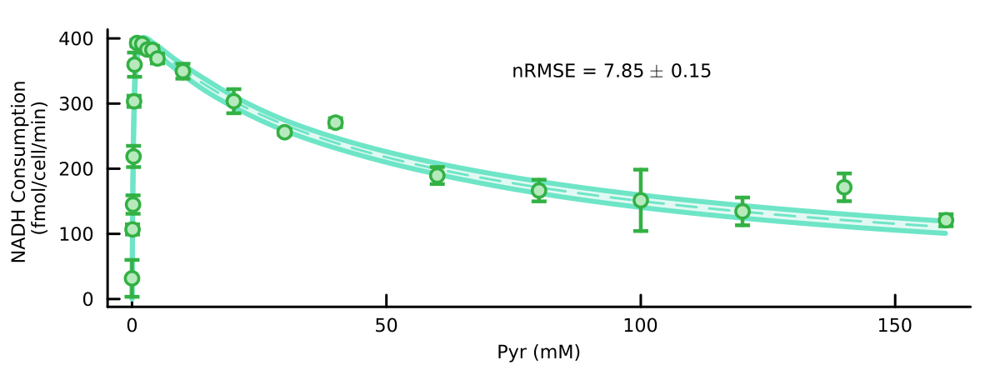

In [314]:
upP4 = [percentile(((((220 .-[smmsI[i,jj][13,3,1]+smmsI[i,jj][13,6,1]+smmsI[i,jj][13,9,1] for jj in 1:smps2])*0.0002)./1e5).*1e+9), 99.5) for i in 1:length(conceI)];
lwP4 = [percentile(((((220 .-[smmsI[i,jj][13,3,1]+smmsI[i,jj][13,6,1]+smmsI[i,jj][13,9,1] for jj in 1:smps2])*0.0002)./1e5).*1e+9),  0.5) for i in 1:length(conceI)];
mdP4 = [(((mean(220 .-[smmsI[i,jj][13,3,1]+smmsI[i,jj][13,6,1]+smmsI[i,jj][13,9,1] for jj in 1:smps2])*0.0002)./1e5).*1e+9) for i in 1:length(conceI)];

ppt2 = plot(size=(400,150), grid=false)

plot!(conceI, upP4, label="", xlabel="Pyr (mM)", ylabel = "NADH Consumption \n(fmol/cell/min)",
    linewidth=2, colour="#6ee5c7")
plot!(conceI, lwP4, label="", xlabel="Pyr (mM)", 
    linewidth=2, colour="#6ee5c7")
plot!(conceI, upP4, fillrange=lwP4, label="", color="#6ee5c7", fillalpha=0.2)
plot!(conceI, mdP4, colour="#6ee5c7", label = "", linewidth = 1, style =:dash)


scatter!(plat[:,1], plat[:,2], yerror = plat[:,3], label = "", markersize=3, markerstrokewidth=4, 
        linewidth=1.5, xguidefontsize=round(25/5), yguidefontsize=round(25/5), tickfontsize=round(25/5), dpi = 300, 
        colour = "#b6eabdff", markerstrokecolor="#33b144ff")


annotate!(75, 350, text("nRMSE = "*string(round(mean(nRMSEPLA), digits = 2))*" "*L"\pm"*" "*string(round(std(nRMSEPLA), digits = 2)),  :black, :left, 5))

savefig(ppt2,"C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure7Stuff\\LDHExperimentSims_AfterInf.svg")

display(ppt2)


### Posterior Plots

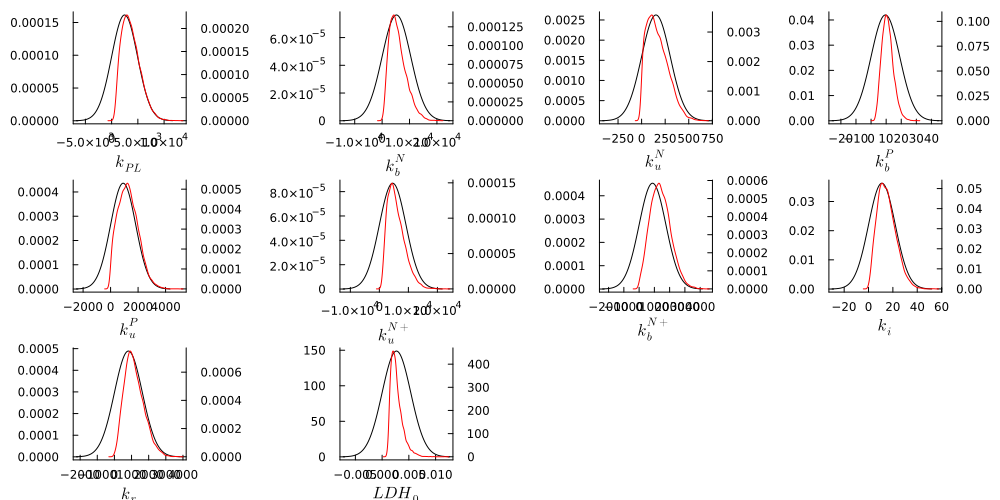

In [7]:
poster_red = poster[:,vcat(3:11, 16)];

labelss = [L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_r",L"LDH_0"]

# prisiD = [Normal(2470,247), Normal(5229,523), Normal(152,15), Normal(9.5,1), Normal(915,91), Normal(4589,459), Normal(879,87), Normal(11,1), Normal(816,81), Normal(0.00268,0.000268)]
prisiD = [Normal(2470,2470), Normal(5229,5229), Normal(152,152), Normal(9.5,9.5), Normal(915,915), Normal(4589,4589), Normal(879,879), Normal(11,11), Normal(816,816), Normal(0.00268,0.00268)]


pripostpl = Array{Any}(undef, length(prisiD))

i = 1
for i in 1:length(prisiD)
    tmp = plot(prisiD[i], label = "", grid=false, xlabel = labelss[i], color="Black")
    plot!(twinx(), kde(poster_red[:,i]), label="", color = "red")

    pripostpl[i] = tmp;

end

plot(pripostpl..., size=(1000,500))

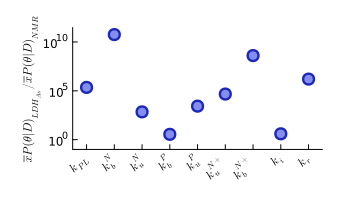

In [24]:
poster3_red = poster3[:,vcat(4:12, 16)];



bigps = transpose(mean(poster3_red, dims=1) .\ mean(poster_red, dims=1))

ppt = scatter(1:length(bigps)-1, bigps[1:end-1], label ="", grid = false, xticks=(1:length(bigps)-1, labelss[1:end-1]), xrotation = 45, 
        ylabel = L" \overline{x} P(\theta | D)_{LDH_{As}} / \overline{x} P(\theta | D)_{NMR}", yscale=:log10, 
        markersize=6, markerstrokewidth=6, 
        linewidth=1.5,  
        colour = "#858eedff", markerstrokecolor="#1b28b9ff",
        size=(350,200), margins=5Plots.mm, yguidefontsize=8, xlim=(0.5,9.5), ylim = (1e-1, 3e11))

savefig(ppt,"C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure7Stuff\\FoldChangeTheta.svg")

display(ppt)

In [14]:
ylims(ppt)

(1.724834176020903, 1.1595243209753622e11)

In [89]:
minimum(bigps[1:end-1])

3.4929064020379004

In [90]:
maximum(bigps[1:end-1])

5.725853906588707e10

# Simulate experiments plot

In [319]:
tsC2 = collect(0:395)[1:5:end]
ts = 0:tsC2[end];
samps = convert.(Int, tsC2)
conceIR = plat[2:end,1]

expind = findfirst(maximum(plat[2:end,2]) .== plat[2:end,2])

smmsIR1 = Array{Any}(undef, smps2)

for jj in 1:smps2

    ivss = [round(conceIR[expind], digits = 1)*1000, 0, 220, 0, smp_NT_NADH[jj, end], 0, 0, 0, 0, 0, round(conceIR[expind], digits = 1)*1000, 0, round(conceIR[expind], digits = 1)*1000*(26*0.12)]
    SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_SolveLDHNoCells(ts, vcat(vcat(smp_NT_NADH[jj, 1:end-5], 1, 26), 0), ivss, samps)

    smmsIR1[jj] = SimulsAll
end


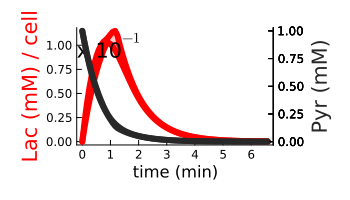

In [320]:
expind = findfirst(maximum(plat[2:end,2]) .== plat[2:end,2])


upP5 = [percentile([smmsIR1[jj][i,10,1] for jj in 1:smps2], 99.5) for i in 1:length(samps)];
lwP5 = [percentile([smmsIR1[jj][i,10,1] for jj in 1:smps2],  0.5) for i in 1:length(samps)];
mdP5 = [mean([smmsIR1[jj][i,10,1] for jj in 1:smps2]) for i in 1:length(samps)];

upP5p = [percentile([smmsIR1[jj][i,11,1] for jj in 1:smps2], 99.5) for i in 1:length(samps)];
lwP5p = [percentile([smmsIR1[jj][i,11,1] for jj in 1:smps2],  0.5) for i in 1:length(samps)];
mdP5p = [mean([smmsIR1[jj][i,11,1] for jj in 1:smps2]) for i in 1:length(samps)];

jj = 4
pppt = plot(label = "", grid = false, title = "", ylabel = "Lac (mM) / cell", xlabel = "time (min)", size=(350,200), margins=5Plots.mm)


plot!(samps./60, upP5./1e+2, label="", 
    linewidth=6, colour="#ff0000", yguidefont = font("#ff0000"))
plot!(samps./60, lwP5./1e+2, label="",
    linewidth=6, colour="#ff0000")
plot!(samps./60, upP5./1e+2, fillrange=lwP5./1e+2, label="", color="#ff0000", fillalpha=0.2)
plot!(samps./60, mdP5./1e+2, colour="#ff0000", label = "", linewidth = 3, style =:dash)

annotate!(1, 1, "x 10"*L"^{-1}")



plot!(twinx(), samps./60, upP5p./1e+3, label="", 
    linewidth=6, colour="#282828", ylabel = "Pyr (mM)", yguidefont = font("#282828"))
plot!(twinx(), samps./60, lwP5p./1e+3, label="",
    linewidth=6, colour="#282828")
plot!(twinx(), samps./60, upP5p./1e+3, fillrange=lwP5p./1e+3, label="", color="#282828", fillalpha=0.2)
plot!(twinx(), samps./60, mdP5p./1e+3, colour="#282828", label = "", linewidth = 3, style =:dash)


savefig(pppt,"C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure7Stuff\\SimChangeTheta.svg")

display(pppt)

## Simulate All States

In [65]:

# Dims = Up/Down, Observable, Experiment
PriorQuant = Array{Any}(undef,2,1,13);
k = 1
for m in 1:13
    lacPirorSims = zeros(size(smmsIR2[1,1])[1], size(smmsIR2)[2])
    [lacPirorSims[:,f] = smmsIR2[1,f][:,m,1] for f in 1:size(smmsIR2)[2] ];

    PriorQuant[1,k,m] = [percentile(lacPirorSims[j,:], 99.5) for j in 1:size(lacPirorSims)[1]]; # Up
    PriorQuant[2,k,m] = [percentile(lacPirorSims[j,:], 0.5 ) for j in 1:size(lacPirorSims)[1]]; # Down
end


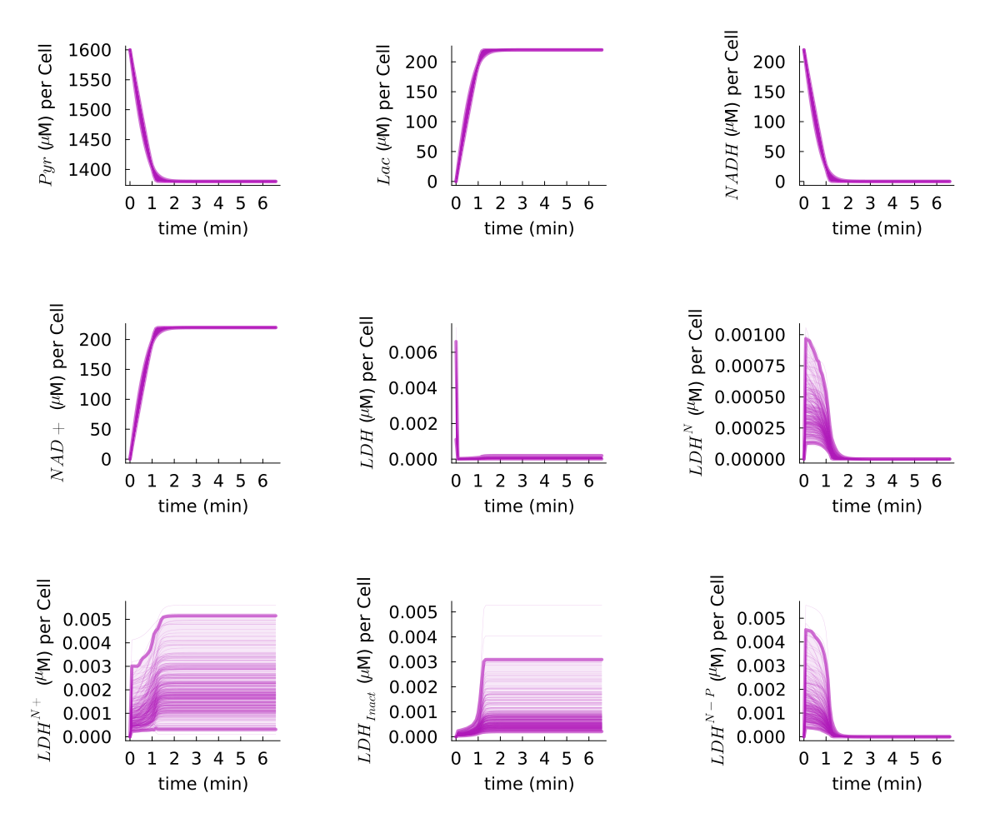

In [86]:
Random.seed!(234569)

ccpal = ["#b21bb9ff"];

stp = 3
ndd = 49
ndd2 = 46

stss = [L"Pyr", L"Lac", L"NADH", L"NAD+", L"LDH", L"LDH^N", L"LDH^{N+}", L"LDH_{Inact}", L"LDH^{N-P}", L"Lac_{HP}", L"Pyr_{HP}", L"Lac_{HP}^{Obs}", L"Pyr_{HP}^{Obs}" ]
i=4 # Experiment
j=3 # Model Iteration

s=3 # Model State

ndd = 80

allXps = Array{Any}(undef, 9)

for s in 1:9

    allXps[s] = plot()

    for j in 1


        tmp1 = PriorQuant[1,j,s];
        tmp2 = PriorQuant[2,j,s];

        plot!(collect(0:5:395)[1:ndd]./60, tmp1[1:ndd], label = "", color = ccpal[j],
            linewidth=4, alpha = 0.6, xlabel = "time (min)", ylabel = stss[s]*" ("*L"\mu"*"M) per Cell", grid = false)
        plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], label = "", color = ccpal[j], linewidth=4, alpha = 0.6)
        plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], fillrange=convert.(Float64, tmp1), color=ccpal[j], fillalpha=0.1, linewidth = 0, label ="")

        for samp in 1:400
            plot!(collect(0:5:395)[1:ndd]./60, smmsIR2[1,samp][:,s,1][1:ndd], label = "", color = ccpal[j], alpha=0.2,  linewidth=0.5)
        end

    end


end

PPA = plot(allXps..., layout=(3,3), size = (1200,1000), margin=12Plots.mm,xtickfont=font(14), 
        ytickfont=font(14), guidefont=font(14), titlefont=font(14))

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\SuppFig32Stuff\\SimsStatesNADH.svg")

display(PPA)

# Bayesian Inference OLD (priors too narrow)

In [ ]:
# dDNP = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ProcessedData\\LacAUCs.csv", DataFrame));
plat = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHActivityResults.csv", DataFrame));

In [ ]:
sts = convert.(Int, zeros(2, length(plat[2:end, 1])))
sts[2, :] .=  60

mes = zeros(2, length(plat[2:end, 1]), 1)
mes[2,:, 1] = plat[2:end, 2]

ers = zeros(2, length(plat[2:end, 1]), 1)
ers[2,:, 1] = plat[2:end, 3]

tss = zeros(2, length(plat[2:end, 1]))
tss[1,:] .+= 1e-20
tss[2,:] .+= 60

Y0us = zeros(13,length(plat[2:end, 1]))
for i in 1:length(plat[2:end, 1])
    Y0us[:,i] = [round(plat[2:end, 1][i], digits = 1)*1000, 0, 220, 0, 0.0004589, 0, 0, 0, 0, 0, round(plat[2:end, 1][i], digits = 1)*1000, 0, round(plat[2:end, 1][i], digits = 1)*1000*(1*0.12)]
end

data_multi = Dict(
        
        "m" => length(plat[2:end, 1]),
        "stslm" => 2,
        "stsl" => reshape(convert.(Int, ones(length(plat[2:end, 1]))*2), 1, length(plat[2:end, 1])),
        "sts" => sts,
        "obser" => 1,
        "obSta" => convert.(Int, ones(1, 1)),
        "Means" => mes,
        "Erros" => ers,
        "tml" => 2,
        "ts" => tss,
        "Y0us" => Y0us,
        "itp" => Vector(zeros(length(plat[2:end, 1]))),
        "ncells" => convert.(Int, ones(1,length(plat[2:end, 1])).*3),
        "nts" => convert.(Int, ones(1,length(plat[2:end, 1])).*1),
        "ScFms" => ones(1,length(plat[2:end, 1])),
        "nmCls" => ones(1,length(plat[2:end, 1])).+3.0e6
    
    )

Dict{String, Any} with 16 entries:
  "Means"  => [0.0 0.0 … 0.0 0.0; 106.784 144.957 … 171.457 120.889;;;]
  "stsl"   => [2 2 … 2 2]
  "obSta"  => [1;;]
  "sts"    => [0 0 … 0 0; 60 60 … 60 60]
  "obser"  => 1
  "Y0us"   => [100.0 200.0 … 140000.0 160000.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 …
  "ts"     => [1.0e-20 1.0e-20 … 1.0e-20 1.0e-20; 60.0 60.0 … 60.0 60.0]
  "itp"    => [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,…
  "ScFms"  => [1.0 1.0 … 1.0 1.0]
  "ncells" => [3 3 … 3 3]
  "stslm"  => 2
  "tml"    => 2
  "Erros"  => [0.0 0.0 … 0.0 0.0; 7.82492 14.1056 … 21.2891 9.23485;;;]
  "m"      => 20
  "nmCls"  => [3.0e6 3.0e6 … 3.0e6 3.0e6]
  "nts"    => [1 1 … 1 1]

In [ ]:
modelpath = "C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\HP_PyrLac_CmpRepresMo_Scallable_NoTransporter.stan";
stream = open(modelpath,"r");
Model = read(stream,String);
close(stream);

StanModel = Stanmodel(name="PyrCompRepr_NoTransport_NADHConsumption_Try1", model=Model, nchains =10,
            num_samples  = 800, num_warmup = 400, printsummary=true);
StanModel.method.save_warmup = true;
StanModel.method.adapt.delta = 0.85;
StanModel.method.algorithm.stepsize = 0.1;
StanModel.method.algorithm.engine.max_depth=10;
StanModel.method.algorithm.stepsize_jitter = 0.5;

In [ ]:
rc, chns, cnames = stan(StanModel, data_multi) 

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: CVode(cvodes_mem, t_final, nv_state_, &t_init, CV_NORMAL) failed with error flag -1: 
The solver took mxstep internal steps but could not reach tout. (in 'c:/IBECPostDocDrive/2024_01_16_NCvsKR/DataProcessingInference/LDHActivityAssey/tmp/PyrCompRepr_NoTransport_NADHConsumption_Try1.stan', line 205, column 6 to column 137)
If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: CVode(cvodes_mem, t_final, nv_state_, &t_init, CV_NORMAL) failed with error flag -1: 
The solver took mxstep internal steps but could not reach tout. (in 'c:/IBECPostDocDrive/2024_01_16_NCvsK

Inference for Stan model: PyrCompRepr_NoTransport_NADHConsumption_Try1_model
10 chains: each with iter=(800,800,800,800,800,800,800,800,800,800); warmup=(400,400,400,400,400,400,400,400,400,400); thin=(1,1,1,1,1,1,1,1,1,1); 12000 iterations saved.

Warmup took (21052, 18519, 20955, 18343, 17946, 17906, 17297, 18454, 21333, 19675) seconds, 53 hours total
Sampling took (26977, 28468, 24529, 31762, 28729, 27925, 26478, 31272, 28735, 26152) seconds, 78 hours total

                    Mean     MCSE   StdDev        5%       50%      95%    N_Eff  N_Eff/s    R_hat

lp__            -1.1e+02  4.1e-02  2.3e+00  -1.1e+02  -1.1e+02 -1.1e+02  3.0e+03  1.1e-02  1.0e+00
accept_stat__       0.95  9.3e-04    0.087      0.76      0.98     1.00  8.7e+03  3.1e-02  1.0e+00
stepsize__         0.090  3.6e-03    0.028     0.048     0.089     0.14  5.8e+01  2.1e-04  1.1e+00
treedepth__          5.4  4.3e-02     0.62       5.0       5.0      6.0  2.0e+02  7.2e-04  1.0e+00
n_leapfrog__          51  1.9e+00     

(0, [-231.466 2.28662e-81 … 0.0 0.00225505; -231.466 3.93575e-23 … 0.0 0.00225505; … ; -111.94 0.998401 … 0.0 0.00271532; -109.781 0.903962 … 0.0 0.00254273;;; -124.918 0.333333 … 0.0 0.0024575; -124.918 3.07631e-131 … 0.0 0.0024575; … ; -110.41 0.932812 … 0.0 0.00263333; -113.117 0.990372 … 0.0 0.00300723;;; -122.025 0.285714 … 0.0 0.00294667; -122.025 1.2631e-20 … 0.0 0.00294667; … ; -111.053 0.968683 … 0.0 0.0028341; -110.513 0.792366 … 0.0 0.00279689;;; -462.244 0.0 … 0.0 0.00233778; -462.244 0.0 … 0.0 0.00233778; … ; -111.467 0.981516 … 0.0 0.00287451; -111.657 0.981646 … 0.0 0.00293453;;; -133.674 3.6187e-24 … 0.0 0.00288715; -133.674 8.5703e-9 … 0.0 0.00288715; … ; -110.457 0.999227 … 0.0 0.00258339; -109.979 0.997322 … 0.0 0.00279595;;; -116.914 1.0 … 0.0 0.0027175; -116.914 0.0 … 0.0 0.0027175; … ; -109.553 0.98888 … 0.0 0.00274658; -114.923 0.989713 … 0.0 0.00292978;;; -127.501 7.45497e-53 … 0.0 0.00274969; -127.501 2.57654e-7 … 0.0 0.00274969; … ; -112.589 0.97517 … 0.0 0.00

In [ ]:
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\ResultsStan\\PyrCompetitiveRepression_NoMCT_NADHCon_Try1.jld", "rc", rc, "chns", chns, "cnames", cnames)

poster = vcat(chns[401:end, end-15:end, 1], chns[401:end, end-15:end, 2], chns[401:end, end-15:end, 3], chns[401:end, end-15:end, 4], chns[401:end, end-15:end, 5], 
              chns[401:end, end-15:end, 6], chns[401:end, end-15:end, 7], chns[401:end, end-15:end, 8], chns[401:end, end-15:end, 9], chns[401:end, end-15:end, 10])
JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\ResultsStan\\PosteriorCompetitiveRepression_NoMCT_NADHCon_Try1.jld", "poster", poster)
CSV.write("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\ResultsStan\\PosteriorCompetitiveRepression_NoMCT_NADHCon_Try1.csv", DataFrame(poster, :auto))

"C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\ResultsStan\\PosteriorCompetitiveRepression_NoMCT_NADHCon_Try1.csv"

In [ ]:
poster = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\ResultsStan\\PosteriorCompetitiveRepression_NoMCT_NADHCon_Try1.csv", DataFrame))

8000×16 Matrix{Float64}:
 51.9806  51.23  2535.35  4671.1   …  3.0e6  1.0  220.0  0.0  0.00273723
 51.9806  51.23  2893.87  4862.83     3.0e6  1.0  220.0  0.0  0.0026353
 51.9806  51.23  2930.06  5037.52     3.0e6  1.0  220.0  0.0  0.00253483
 51.9806  51.23  2810.91  4789.47     3.0e6  1.0  220.0  0.0  0.0025813
 51.9806  51.23  2206.79  5608.44     3.0e6  1.0  220.0  0.0  0.00280854
 51.9806  51.23  2795.02  5879.93  …  3.0e6  1.0  220.0  0.0  0.00257497
 51.9806  51.23  2911.19  5860.05     3.0e6  1.0  220.0  0.0  0.00256516
 51.9806  51.23  2642.75  6099.08     3.0e6  1.0  220.0  0.0  0.00258686
 51.9806  51.23  2677.57  5739.05     3.0e6  1.0  220.0  0.0  0.00264889
 51.9806  51.23  2767.3   5893.57     3.0e6  1.0  220.0  0.0  0.00263287
 51.9806  51.23  2696.69  5500.33  …  3.0e6  1.0  220.0  0.0  0.00266694
 51.9806  51.23  2401.06  4769.55     3.0e6  1.0  220.0  0.0  0.00265298
 51.9806  51.23  2461.35  4249.83     3.0e6  1.0  220.0  0.0  0.00266551
  ⋮                         

In [ ]:
# using CairoMakie
# using PairPlots
# using DataFrames

# poster_red = poster[:,vcat(3:11, 16)];

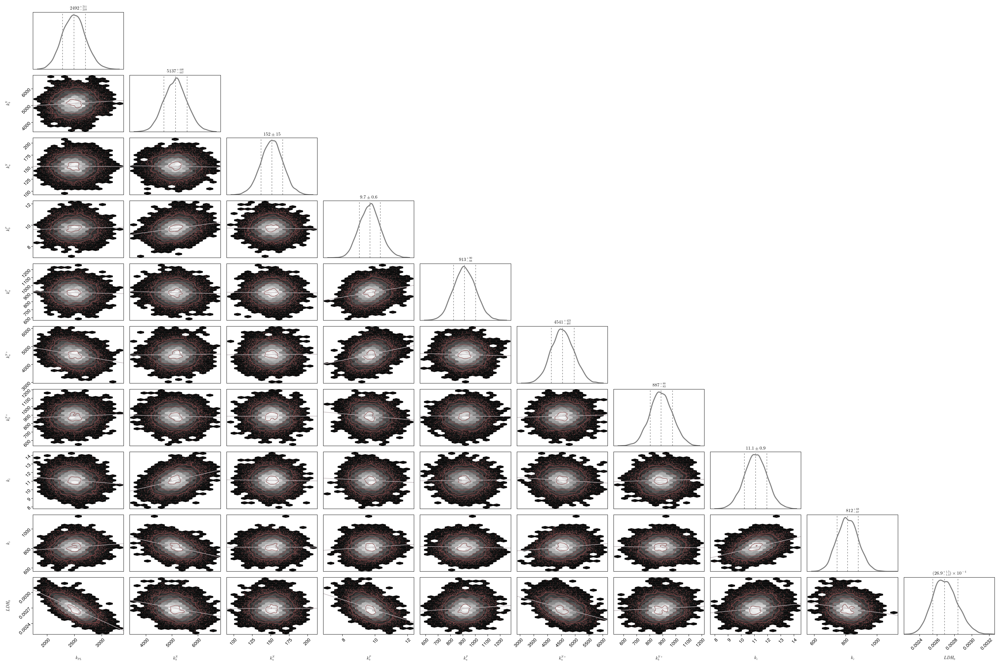

In [ ]:
# label = [L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_r",L"LDH_0"]

# df = DataFrame(poster_red, :auto)

# fig = Figure(size=(3000,2000))
# # 
# pairplot(fig[1,1], df => (
#     PairPlots.HexBin(colormap=:grays, alpha=1), # RdYlGn
#     PairPlots.Scatter(filtersigma=2, color="#884a4aff", markersize=3, alpha=0.65),
#     PairPlots.Contour(color="#884a4aff", alpha=0.85),
#     # # New:
    
#     PairPlots.MarginConfidenceLimits(),
#     PairPlots.MarginDensity(color="gray", linewidth=3),
#     PairPlots.TrendLine(color="#c0b5b9ff"), # default is red
    
# ), 
# labels = Dict(:x1 => label[1],:x2 => label[2],:x3 => label[3],:x4 => label[4],:x5 => label[5],:x6 => label[6],:x7 => label[7],:x8 => label[8],:x9 => label[9],:x10 => label[10]))

# # save("D:\\David\\BayesianInferencesInVivoScripts\\Figures\\SuppFig6Stuff\\PosteriorCovariance_InitialExperiment.svg", fig)


# fig

### Simulate and plot prediction

In [ ]:
Random.seed!(654358)
smps2 = 400
ins = sample(1:8000, smps2, replace = false)

smp_NT_NADH = poster[ins, :];


In [ ]:
tsC2 = collect(0:395)[1:5:end]
ts = 0:tsC2[end];
samps = convert.(Int, tsC2)
conceI = collect(0.001:0.1:160)

rep = false

if !isfile("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_NT_Inf.jld") || rep == true

    println(1)

    smmsI = Array{Any}(undef, length(conceI), smps2)

    for mm in 1:length(conceI)
        for jj in 1:smps2

            ivss = [round(conceI[mm], digits = 1)*1000, 0, 220, 0, smp_NT_NADH[jj, end], 0, 0, 0, 0, 0, round(conceI[mm], digits = 1)*1000, 0, round(conceI[mm], digits = 1)*1000*(26.791799999999974*0.12)]
            SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_SolveLDHNoCells(ts, vcat(smp_NT_NADH[jj, 1:end-3], 0), ivss, samps)

            smmsI[mm, jj] = SimulsAll
        end
    end

    JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_NT_Inf.jld", "smmsI", smmsI)
else
    
    smmsI = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_NT_Inf.jld")["smmsI"];
    println(2)
end

1


In [ ]:
tsC2 = collect(0:395)[1:5:end]
ts = 0:tsC2[end];
samps = convert.(Int, tsC2)
conceIR = plat[2:end,1]

rep = false

if !isfile("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_NTR_Inf.jld") || rep == true

    println(1)

    smmsIR = Array{Any}(undef, length(conceIR), smps2)

    for mm in 1:length(conceIR)
        for jj in 1:smps2

            ivss = [round(conceIR[mm], digits = 1)*1000, 0, 220, 0, smp_NT_NADH[jj, end], 0, 0, 0, 0, 0, round(conceIR[mm], digits = 1)*1000, 0, round(conceIR[mm], digits = 1)*1000*(26.791799999999974*0.12)]
            SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_SolveLDHNoCells(ts, vcat(smp_NT_NADH[jj, 1:end-3], 0), ivss, samps)

            smmsIR[mm, jj] = SimulsAll
        end
    end

    JLD2.save("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_NTR_Inf.jld", "smmsIR", smmsIR)
else
    
    smmsIR = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHActivityAssey\\Results\\LDHExpSims_NTR_Inf.jld")["smmsIR"];
    println(2)
end

1


In [ ]:
simsa = zeros(smps2, length(conceIR))
for h in 1:length(conceIR)    
    for jj in 1:smps2
        simsa[jj,h] = ((((220 .-smmsIR[h,jj][13,3,1]+smmsIR[h,jj][13,6,1]+smmsIR[h,jj][13,9,1] )*0.0002)./1e5).*1e+9)
    end
end

nRMSEPLA = [sum(((transpose(plat[:,2])[2:end] - simsa[h,:]).^2) ./ transpose(plat[:,3])[2:end].^2)/length(simsa[h,:]) + log(14*log(length(simsa[h,:]))) for h in 1:smps2];

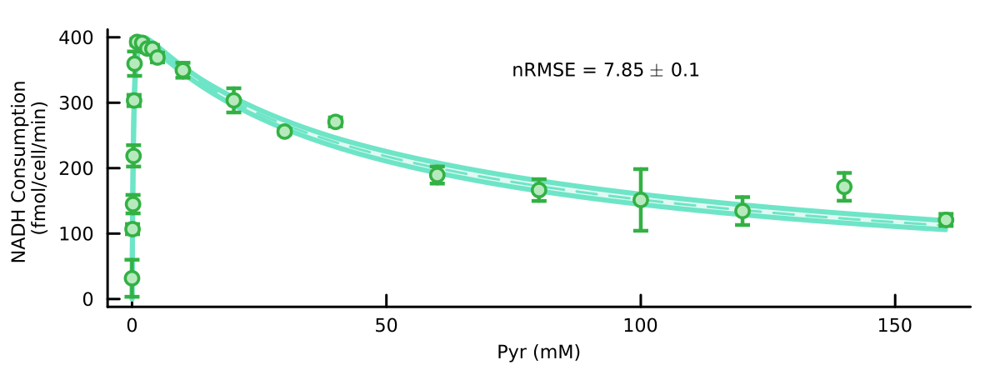

In [ ]:
upP4 = [percentile(((((220 .-[smmsI[i,jj][13,3,1]+smmsI[i,jj][13,6,1]+smmsI[i,jj][13,9,1] for jj in 1:smps2])*0.0002)./1e5).*1e+9), 99.5) for i in 1:length(conceI)];
lwP4 = [percentile(((((220 .-[smmsI[i,jj][13,3,1]+smmsI[i,jj][13,6,1]+smmsI[i,jj][13,9,1] for jj in 1:smps2])*0.0002)./1e5).*1e+9),  0.5) for i in 1:length(conceI)];
mdP4 = [(((mean(220 .-[smmsI[i,jj][13,3,1]+smmsI[i,jj][13,6,1]+smmsI[i,jj][13,9,1] for jj in 1:smps2])*0.0002)./1e5).*1e+9) for i in 1:length(conceI)];

ppt2 = plot(size=(400,150), grid=false)

plot!(conceI, upP4, label="", xlabel="Pyr (mM)", ylabel = "NADH Consumption \n(fmol/cell/min)",
    linewidth=2, colour="#6ee5c7")
plot!(conceI, lwP4, label="", xlabel="Pyr (mM)", 
    linewidth=2, colour="#6ee5c7")
plot!(conceI, upP4, fillrange=lwP4, label="", color="#6ee5c7", fillalpha=0.2)
plot!(conceI, mdP4, colour="#6ee5c7", label = "", linewidth = 1, style =:dash)


scatter!(plat[:,1], plat[:,2], yerror = plat[:,3], label = "", markersize=3, markerstrokewidth=4, 
        linewidth=1.5, xguidefontsize=round(25/5), yguidefontsize=round(25/5), tickfontsize=round(25/5), dpi = 300, 
        colour = "#b6eabdff", markerstrokecolor="#33b144ff")


annotate!(75, 350, text("nRMSE = "*string(round(mean(nRMSEPLA), digits = 2))*" "*L"\pm"*" "*string(round(std(nRMSEPLA), digits = 2)),  :black, :left, 5))

savefig(ppt2,"C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure7Stuff\\LDHExperimentSims_AfterInf.svg")

display(ppt2)


### Posterior Plots

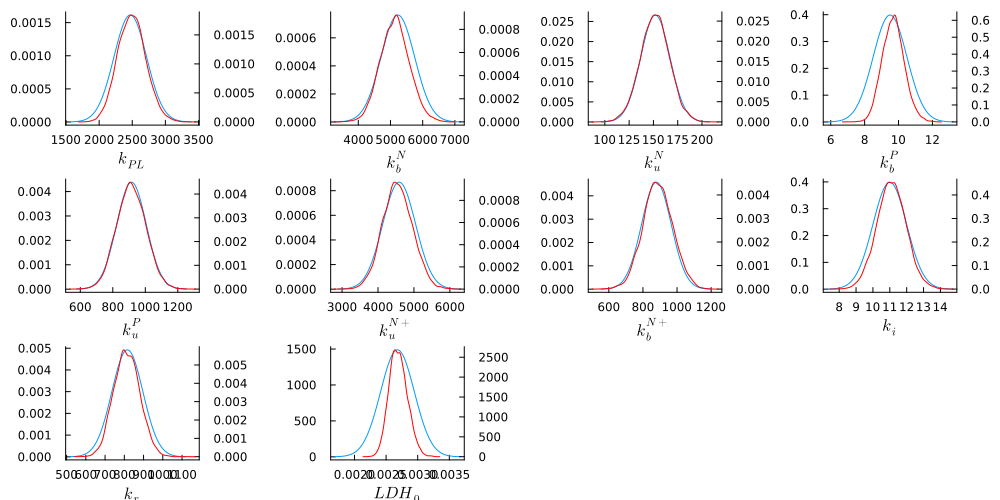

In [ ]:
poster_red = poster[:,vcat(3:11, 16)];

labelss = [L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_r",L"LDH_0"]

prisiD = [Normal(2470,247), Normal(5229,523), Normal(152,15), Normal(9.5,1), Normal(915,91), Normal(4589,459), Normal(879,87), Normal(11,1), Normal(816,81), Normal(0.00268,0.000268)]


pripostpl = Array{Any}(undef, length(prisiD))

i = 1
for i in 1:length(prisiD)
    tmp = plot(prisiD[i], label = "", grid=false, xlabel = labelss[i])
    plot!(twinx(), kde(poster_red[:,i]), label="", color = "red")

    pripostpl[i] = tmp;

end

plot(pripostpl..., size=(1000,500))

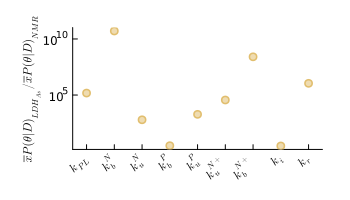

In [ ]:
poster3_red = poster3[:,vcat(4:12, 16)];



bigps = transpose(mean(poster3_red, dims=1) .\ mean(poster_red, dims=1))

ppt = scatter(1:length(bigps)-1, bigps[1:end-1], label ="", grid = false, xticks=(1:length(bigps)-1, labelss[1:end-1]), xrotation = 45, 
        ylabel = L" \overline{x} P(\theta | D)_{LDH_{As}} / \overline{x} P(\theta | D)_{NMR}", yscale=:log10, 
        markersize=4, markerstrokewidth=4, 
        linewidth=1.5,  
        colour = "#efdcb1ff", markerstrokecolor="#e1be6eff",
        size=(350,200), margins=5Plots.mm, yguidefontsize=8, xlim=(0.5,9.5))

savefig(ppt,"C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure7Stuff\\FoldChangeTheta.svg")

display(ppt)

# Simulate experiments plot

In [ ]:
tsC2 = collect(0:395)[1:5:end]
ts = 0:tsC2[end];
samps = convert.(Int, tsC2)
conceIR = plat[2:end,1]

expind = findfirst(maximum(plat[2:end,2]) .== plat[2:end,2])

smmsIR1 = Array{Any}(undef, smps2)

for jj in 1:smps2

    ivss = [round(conceIR[expind], digits = 1)*1000, 0, 220, 0, smp_NT_NADH[jj, end], 0, 0, 0, 0, 0, round(conceIR[expind], digits = 1)*1000, 0, round(conceIR[expind], digits = 1)*1000*(26*0.12)]
    SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_SolveLDHNoCells(ts, vcat(vcat(smp_NT_NADH[jj, 1:end-5], 1, 26), 0), ivss, samps)

    smmsIR1[jj] = SimulsAll
end


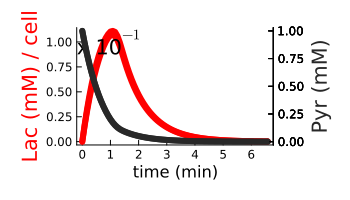

In [ ]:
expind = findfirst(maximum(plat[2:end,2]) .== plat[2:end,2])


upP5 = [percentile([smmsIR1[jj][i,10,1] for jj in 1:smps2], 99.5) for i in 1:length(samps)];
lwP5 = [percentile([smmsIR1[jj][i,10,1] for jj in 1:smps2],  0.5) for i in 1:length(samps)];
mdP5 = [mean([smmsIR1[jj][i,10,1] for jj in 1:smps2]) for i in 1:length(samps)];

upP5p = [percentile([smmsIR1[jj][i,11,1] for jj in 1:smps2], 99.5) for i in 1:length(samps)];
lwP5p = [percentile([smmsIR1[jj][i,11,1] for jj in 1:smps2],  0.5) for i in 1:length(samps)];
mdP5p = [mean([smmsIR1[jj][i,11,1] for jj in 1:smps2]) for i in 1:length(samps)];

jj = 4
pppt = plot(label = "", grid = false, title = "", ylabel = "Lac (mM) / cell", xlabel = "time (min)", size=(350,200), margins=5Plots.mm)


plot!(samps./60, upP5./1e+2, label="", 
    linewidth=6, colour="#ff0000", yguidefont = font("#ff0000"))
plot!(samps./60, lwP5./1e+2, label="",
    linewidth=6, colour="#ff0000")
plot!(samps./60, upP5./1e+2, fillrange=lwP5./1e+2, label="", color="#ff0000", fillalpha=0.2)
plot!(samps./60, mdP5./1e+2, colour="#ff0000", label = "", linewidth = 3, style =:dash)

annotate!(1, 1, "x 10"*L"^{-1}")



plot!(twinx(), samps./60, upP5p./1e+3, label="", 
    linewidth=6, colour="#282828", ylabel = "Pyr (mM)", yguidefont = font("#282828"))
plot!(twinx(), samps./60, lwP5p./1e+3, label="",
    linewidth=6, colour="#282828")
plot!(twinx(), samps./60, upP5p./1e+3, fillrange=lwP5p./1e+3, label="", color="#282828", fillalpha=0.2)
plot!(twinx(), samps./60, mdP5p./1e+3, colour="#282828", label = "", linewidth = 3, style =:dash)


savefig(pppt,"C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure7Stuff\\SimChangeTheta.svg")

display(pppt)